# TourShield - Classificação de intenções | TP4
**Helena Gomes e Maria Paula | 21/11/2026**

Continuação do protocolo TP3: CLINC150, mesmas 20 classes e splits oficiais.
TF-IDF + LogisticRegression L2; somente message é feature. O GridSearchCV usa
PredefinedSplit: 2.000 treino / 400 validação, com refit final nos 2.400 exemplos.
Teste de 600 mensagens só após congelar parâmetros. A EDA anterior já descreveu
o teste: resultados são internos ao benchmark, não validação externa intocada.

In [1]:
from pathlib import Path
import hashlib
import json
import time
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score, RocCurveDisplay)

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path(__file__).resolve().parents[1]
OUT = ROOT / 'reports/tp4'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(ROOT / 'models').mkdir(exist_ok=True)
data = pd.read_csv(ROOT / 'data/tourshield_clean.csv')
assert len(data) == 3000 and data['intent'].nunique() == 20
assert not data['message'].str.strip().str.lower().duplicated().any()
train, val, test = [data[data['split'].eq(s)].copy() for s in ['train','val','test']]
assert [len(x) for x in [train,val,test]] == [2000,400,600]
display(data.groupby(['intent','split']).size().unstack())
print('Python:',platform.python_version(),'| scikit-learn:',sklearn.__version__)

split,test,train,val
intent,,,
book_flight,30,100,20
book_hotel,30,100,20
cancel_reservation,30,100,20
car_rental,30,100,20
carry_on,30,100,20
confirm_reservation,30,100,20
current_location,30,100,20
directions,30,100,20
distance,30,100,20


Python: 3.12.10 | scikit-learn: 1.9.1


## Baselines e busca sem vazamento
A configuração inicial vem do TP3: ngram=(1,2), min_df=2, max_features=10.000,
sublinear_tf=True, C=1. Baseline majoritária: DummyClassifier. A base é balanceada:
macro-F1 diferencia cobertura de classes mesmo quando acurácia parece aceitável.
A grade tem **dois parâmetros com três valores cada**: min_df=[1,2,3], C=[0.1,1,10].
PredefinedSplit contém um holdout de validação, não CV de múltiplos folds; preserva
o protocolo já definido. Empates exatos seguem ordem da grade (C menor primeiro).

In [2]:
def make_pipeline():
    return Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1,2), min_df=2,
                                max_features=10000, sublinear_tf=True)),
        ('classifier', LogisticRegression(C=1, solver='lbfgs', max_iter=2000, random_state=42))])

initial = make_pipeline().fit(train['message'],train['intent'])
initial_val_f1 = f1_score(val['intent'],initial.predict(val['message']),average='macro')
development = pd.concat([train,val],ignore_index=True)
folds = PredefinedSplit(np.r_[np.full(len(train),-1),np.zeros(len(val),dtype=int)])
grid = GridSearchCV(make_pipeline(), {'tfidf__min_df':[1,2,3], 'classifier__C':[.1,1,10]},
                    cv=folds, scoring={'f1_macro':'f1_macro','accuracy':'accuracy'}, refit='f1_macro',
                    n_jobs=1, return_train_score=True, error_score='raise')
started = time.perf_counter()
grid.fit(development['message'],development['intent'])
training_seconds = time.perf_counter()-started
model = grid.best_estimator_
cv_table = pd.DataFrame(grid.cv_results_)[['param_classifier__C','param_tfidf__min_df',
    'mean_train_f1_macro','mean_test_f1_macro','mean_test_accuracy','rank_test_f1_macro']]
display(cv_table)
cv_table.to_csv(OUT / 'grid_search.csv',index=False)
display(Markdown(f'**Melhores parâmetros:** {grid.best_params_}. Macro-F1 validação: '
                 f'{grid.best_score_:.4f}; inicial: {initial_val_f1:.4f}; '
                 f'ganho: {(grid.best_score_-initial_val_f1)*100:.2f} pontos percentuais. '
                 'Esse ganho compara os mesmos 2.000 exemplos de treino e 400 de validação; '
                 'o refit posterior amplia o treino final, sem tocar no teste.'))

,param_classifier__C,param_tfidf__min_df,mean_train_f1_macro,mean_test_f1_macro,mean_test_accuracy,rank_test_f1_macro
0,0.1,1,0.968501,0.905595,0.9075,9
1,0.1,2,0.960474,0.910179,0.9125,7
2,0.1,3,0.955933,0.909670,0.9125,8
3,1.0,1,0.996002,0.952109,0.9525,3
4,1.0,2,0.995000,0.949490,0.9500,4
5,1.0,3,0.990497,0.944343,0.9450,6
6,10.0,1,0.999500,0.957412,0.9575,1
7,10.0,2,0.999500,0.947514,0.9475,5
8,10.0,3,0.999500,0.952601,0.9525,2


**Melhores parâmetros:** {'classifier__C': 10, 'tfidf__min_df': 1}. Macro-F1 validação: 0.9574; inicial: 0.9495; ganho: 0.79 pontos percentuais. Esse ganho compara os mesmos 2.000 exemplos de treino e 400 de validação; o refit posterior amplia o treino final, sem tocar no teste.

## Avaliação final: modelo, configuração inicial e DummyClassifier
Ambos os pipelines são reajustados nos mesmos 2.400 exemplos para isolar o efeito
dos hiperparâmetros no teste. ROC-AUC multiclasse usa one-vs-rest macro e probabilidades
na ordem de classes do estimador. Não aplicar AUC a rótulos discretos. AUC alta de
ranking não demonstra calibração nem desempenho fora das 20 intenções conhecidas.

,modelo,accuracy,macro_f1,weighted_f1,roc_auc_ovr_macro
0,Dummy majoritária,0.050000,0.004762,0.004762,0.500000
1,Inicial TP3,0.925000,0.923979,0.923979,0.997365
2,GridSearch final,0.936667,0.935555,0.935555,0.998070


,precision,recall,f1-score,support
book_flight,1.000000,1.000000,1.000000,30.0
book_hotel,0.967742,1.000000,0.983607,30.0
cancel_reservation,1.000000,1.000000,1.000000,30.0
car_rental,1.000000,0.966667,0.983051,30.0
carry_on,1.000000,0.933333,0.965517,30.0
confirm_reservation,1.000000,1.000000,1.000000,30.0
current_location,0.848485,0.933333,0.888889,30.0
directions,0.852941,0.966667,0.906250,30.0
distance,1.000000,0.666667,0.800000,30.0
flight_status,0.857143,1.000000,0.923077,30.0


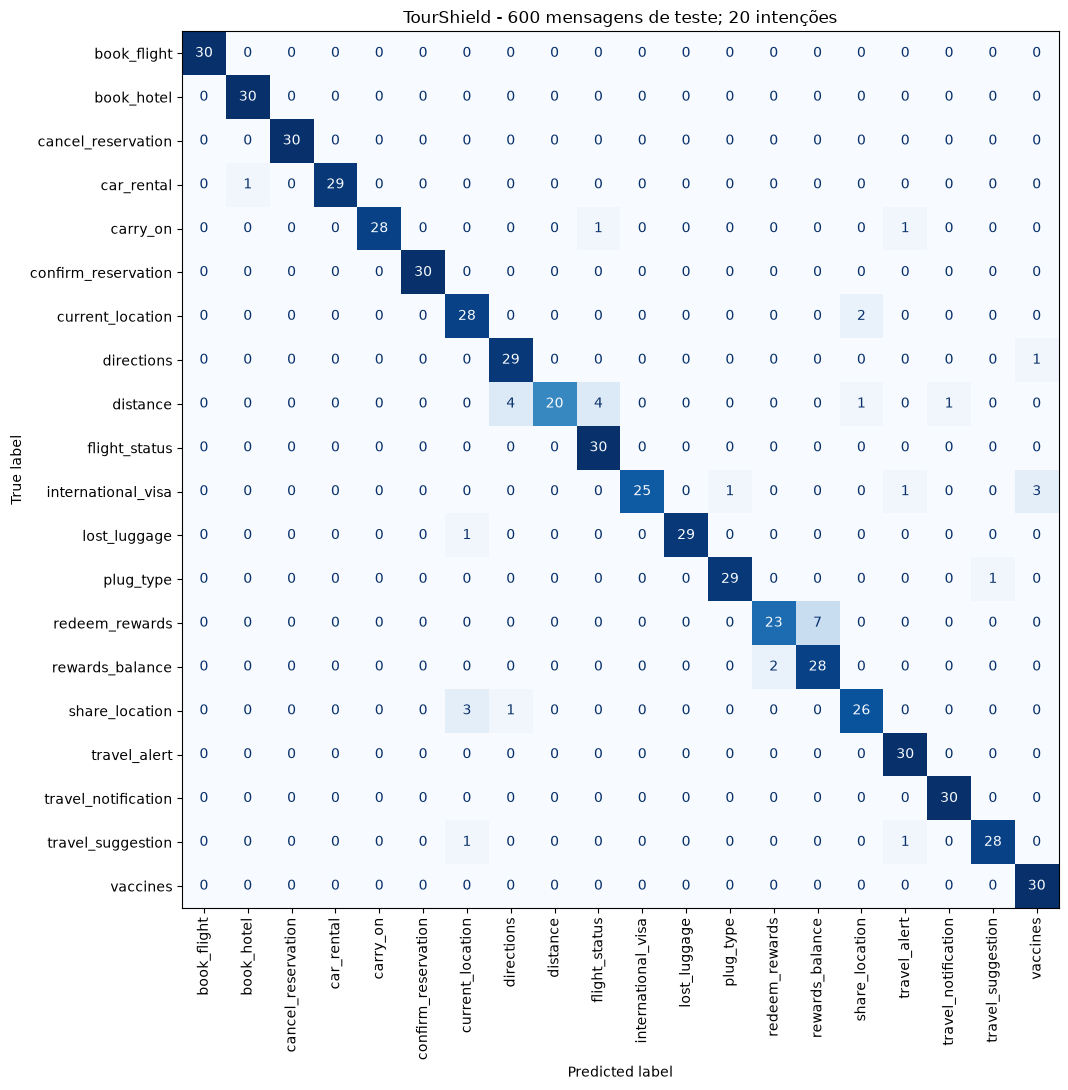

In [3]:
initial.fit(development['message'],development['intent'])
dummy = DummyClassifier(strategy='most_frequent').fit(development['message'],development['intent'])
rows=[]
for name, estimator in [('Dummy majoritária',dummy),('Inicial TP3',initial),('GridSearch final',model)]:
    prediction = estimator.predict(test['message'])
    proba = estimator.predict_proba(test['message'])
    rows.append({'modelo':name,'accuracy':accuracy_score(test['intent'],prediction),
                 'macro_f1':f1_score(test['intent'],prediction,average='macro'),
                 'weighted_f1':f1_score(test['intent'],prediction,average='weighted'),
                 'roc_auc_ovr_macro':roc_auc_score(test['intent'],proba,labels=estimator.classes_,
                                                  multi_class='ovr',average='macro')})
metrics = pd.DataFrame(rows)
display(metrics)
metrics.to_csv(OUT / 'metrics.csv',index=False)
pred = model.predict(test['message'])
probabilities = model.predict_proba(test['message'])
report = classification_report(test['intent'],pred,output_dict=True,zero_division=0)
per_class = pd.DataFrame(report).T.loc[model.classes_]
display(per_class)
per_class.to_csv(OUT / 'metrics_by_class.csv')
matrix = confusion_matrix(test['intent'],pred,labels=model.classes_)
fig,ax=plt.subplots(figsize=(12,11))
ConfusionMatrixDisplay(matrix,display_labels=model.classes_).plot(ax=ax,cmap='Blues',colorbar=False,xticks_rotation=90,values_format='d')
ax.set_title('TourShield - 600 mensagens de teste; 20 intenções')
fig.tight_layout()
fig.savefig(OUT / 'figures/confusion_matrix.png',dpi=145)
plt.show()
plt.close(fig)

## ROC por classe e erros
A tabela registra todas as classes; quatro curvas ilustrativas tornam o gráfico
legível. Probabilidade máxima é uma estimativa do classificador, não garantia de
acerto. Não há rejeição out-of-scope validada; o modelo sempre seleciona uma classe.

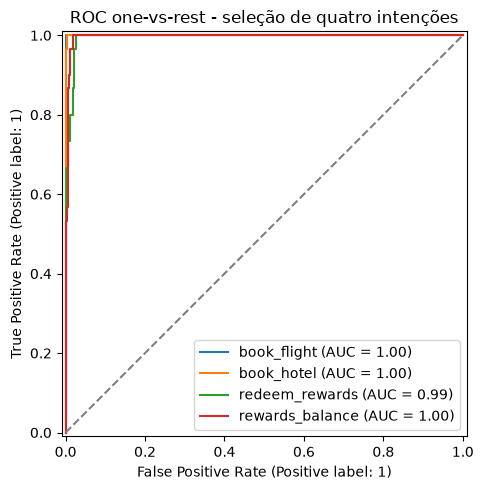

,sample_id,message,intent,predicted,probability
93,clinc-18903,what's the mileage to get the the taj mahal in...,distance,directions,0.497359
100,clinc-18910,is it going to be much longer until i reach th...,distance,travel_notification,0.556893
101,clinc-18911,am i close to arriving at the post office,distance,directions,0.385840
103,clinc-18913,when will i arrive at hy-vee,distance,flight_status,0.374308
107,clinc-18917,when will the bus get me to vermont,distance,directions,0.432027
113,clinc-18923,give me an eta on when i will arrive at my des...,distance,flight_status,0.364516
115,clinc-18925,when will i get to orlando,distance,flight_status,0.534198
116,clinc-18926,how much farther is orlando from my location,distance,share_location,0.268370
117,clinc-18927,do i have a ways to go or am i close to gettin...,distance,directions,0.229321
119,clinc-18929,can you tell me about what time i should be ar...,distance,flight_status,0.237687


In [4]:
auc_rows=[]
fig,ax=plt.subplots(figsize=(8,5))
for i,label in enumerate(model.classes_):
    binary=(test['intent']==label).astype(int)
    auc_rows.append({'intent':label,'auc_ovr':roc_auc_score(binary,probabilities[:,i])})
    if label in ['book_hotel','book_flight','redeem_rewards','rewards_balance']:
        RocCurveDisplay.from_predictions(binary,probabilities[:,i],name=label,ax=ax)
ax.plot([0,1],[0,1],'--',color='gray')
ax.set_title('ROC one-vs-rest - seleção de quatro intenções')
fig.tight_layout()
fig.savefig(OUT / 'figures/roc.png',dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(auc_rows).to_csv(OUT / 'auc_by_class.csv',index=False)
errors=test[['sample_id','message','intent']].copy()
errors['predicted']=pred
errors['probability']=probabilities.max(axis=1)
errors=errors[errors['intent']!=errors['predicted']]
display(errors.head(10))
errors.to_csv(OUT / 'errors.csv',index=False)

## Serialização, integridade e limites
O arquivo joblib é carregado somente do diretório local models/, após conferir
SHA-256 e versão do scikit-learn. Hash detecta corrupção, não protege contra alguém
que consiga substituir modelo e manifesto; a origem deve continuar confiável.
Não aceitar uploads de pickle/joblib. O modelo não decide fraude, elegibilidade,
pagamento ou localização. Português, multi-intenção e entradas desconhecidas não
foram validados; manter atendimento humano nessas situações.

In [5]:
artifact=ROOT / 'models/intent_classifier.joblib'
joblib.dump(model,artifact,compress=3)
manifest={'version':'tourshield-intents-tp4-v1','sha256':hashlib.sha256(artifact.read_bytes()).hexdigest(),
          'sklearn_version':sklearn.__version__,'classes':model.classes_.tolist(),
          'dataset_sha256':hashlib.sha256((ROOT/'data/tourshield_clean.csv').read_bytes()).hexdigest(),
          'best_params':grid.best_params_,'language':'en','train':2000,'val':400,'test':600,'final_fit':2400}
(ROOT/'models/manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
summary={'best_params':grid.best_params_,'initial_validation_macro_f1':initial_val_f1,
         'best_validation_macro_f1':float(grid.best_score_),
         'validation_gain_pp':float(100*(grid.best_score_-initial_val_f1)),
         'test_metrics':rows,'training_seconds':training_seconds,'errors':len(errors),
         'artifact_bytes':artifact.stat().st_size,'manifest':manifest,
         'weakest_classes':per_class.sort_values('f1-score').head(3).reset_index().to_dict('records')}
(OUT/'classification_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
assert np.allclose(joblib.load(artifact).predict_proba(test['message']),probabilities)
display(Markdown(f'**Conclusão:** macro-F1 teste={rows[-1]["macro_f1"]:.4f}; '
                 f'baseline={rows[0]["macro_f1"]:.4f}; {len(errors)} erros em 600 mensagens. '
                 'Analisar as classes de menor F1 antes de expandir o domínio. '
                 'A API retorna apenas intenção, probabilidade e versão, sem autorizar ações.'))
print('Modelo serializado e recarga verificada:',artifact.name)

**Conclusão:** macro-F1 teste=0.9356; baseline=0.0048; 38 erros em 600 mensagens. Analisar as classes de menor F1 antes de expandir o domínio. A API retorna apenas intenção, probabilidade e versão, sem autorizar ações.

Modelo serializado e recarga verificada: intent_classifier.joblib
